# 위고비 확산이 기존 담낭수술 급부에 미치는 영향

**세마글루타이드 담석증 근거 × 국내 수술 전환율 × 치료 지속·중단·재개 경로**

이 노트북은 위고비 치료 노출이 늘어날 때 추가로 발생할 수 있는 담석증과 그중 담낭절제술로 이어지는 건수, 가상 수술급부의 증가액을 계산한다. 결과는 **치료 적격·미사용 가상 가입자 1,000명** 기준이다.

두 효과를 구분한다.

- **시장 확산 효과:** `market_low`와 `market_high`의 치료 경로 차이
- **특약 귀속 효과:** 기준 시나리오에서 `특약 있음(A+B)`과 `특약 없음(A)`의 치료 경로 차이

> 담낭질환 진단 전체가 아니라 **담석증 → 담낭절제술 → 수술급부**의 연결만 분석한다. 임상시험에는 담낭절제술 자체가 보고되지 않아 국내 전환율을 별도로 적용한다.

## 1. 임상 근거와 적용 범위

| 근거 | 위고비군 | 대조군 | 효과값 | 이번 분석의 역할 |
|---|---:|---:|---:|---|
| Safwan et al. 2025, 담석증 | 53 / 2,325 | 13 / 1,429 | RR 2.59 (95% CI 1.40~4.82) | 기준 임상효과와 민감도 |
| Kommu & Berg 2024, 담석증 | 논문 내 통합 | 논문 내 통합 | OR 2.06 (95% CI 1.04~4.08) | 독립값이 아닌 교차 확인 |

- 두 메타분석은 포함 임상시험이 겹치므로 효과값을 평균하거나 합치지 않는다.
- Safwan의 담석증 결과를 주근거로 사용한다. RR을 치료 중 일정한 위험배수로 바꾸는 것은 노출 모형 연결을 위한 연구 가정이다.
- Safwan의 전체 담낭 이상반응은 본문 분자 337건과 그림 합계 377건이 서로 달라 사용하지 않는다. 담석증 53건·13건은 이 불일치와 별개다.
- 두 논문 모두 담낭절제술 건수를 별도로 보고하지 않았다. 따라서 임상 RR만으로 수술보험금을 직접 산출할 수 없다.

**출처**

- Safwan et al. *Safety of semaglutide for weight loss: a systematic review and meta-analysis*. Annals of Saudi Medicine 2025. https://doi.org/10.5144/0256-4947.2025.129
- Kommu & Berg. *Efficacy and safety of semaglutide in non-diabetic adults with overweight or obesity*. Obesity Reviews 2024. https://doi.org/10.1111/obr.13792

## 2. 국내 담낭절제술 전환 가정

국민건강보험공단 표본코호트 연구에서 담석증 환자 13,069명 중 2,706명이 담낭절제술을 받아 관찰기간 내 비율은 **20.7%**였다. 이를 기준 전환율로 사용한다.

| 시나리오 | 담석증 후 수술 전환율 | 용도 |
|---|---:|---|
| 낮음 | 10.0% | 무증상·비수술 관리가 많은 경우 |
| 기준 | 20.7% | 국내 NHIS-NSC 직접 코호트 비율 |
| 높음 | 35.0% | 국내 진단·수술량 자료의 규모 교차 확인 |
| 극단 상한 | 100.0% | 담석증이 모두 수술로 이어지는 계산상 상한 |

기준 20.7%는 위고비 사용자의 전환율이 아니라 국내 담석증 환자 코호트의 관찰값이다. 질환 중증도, 추적기간과 수술 적응증이 다를 수 있으므로 10%·35% 민감도를 함께 본다. 100%는 현실적 기준이 아니라 최대 노출 확인용이다.

**출처**

- Korean NHIS-NSC cohort, *Impact of cholecystectomy on acute coronary syndrome according to metabolic condition*. Scientific Reports 2023. https://doi.org/10.1038/s41598-023-33440-4
- Korean nationwide NHIS study, *The incidence and management of cholelithiasis in Korea*. Annals of Surgical Treatment and Research 2022. https://doi.org/10.4174/astr.2022.102.4.205

## 3. 계산 조건과 핵심 가정

| 구분 | 기준값 | 의미 |
|---|---:|---|
| 가상 가입자 | 1,000명 | 치료 적격·비당뇨·가입 전 미사용 코호트 |
| 관찰기간 | 10년 | 치료 시작 및 담낭수술 영향 관찰 |
| 임상 RR | 2.59 | Safwan 담석증 메타분석 점추정치 |
| 대조군 담석증 위험 | 13 / 1,429 | 임상시험 통합 대조군 위험 |
| 임상위험 환산기간 | 68주 | 여러 시험의 추적기간이 달라 둔 기준 가정; 52·104주 비교 |
| 수술 전환율 | 20.7% | 국내 NHIS-NSC 관찰값 |
| 가상 수술급부 | 1,000만 원 | 첫 담낭절제술 1회 지급 가정 |
| 할인율 | 연 3% | 기존 사망·심혈관 영향 분석과 통일 |
| 수술 시점 | 담석증 발생일 | 지연자료가 없어 즉시 수술·지급으로 단순화 |

치료 중 기대인원은 기존 치료경로 모형의 지속·중단·재개를 그대로 사용한다. 각 날짜의 추가 담석증은 다음과 같이 계산한다.

$$
\Delta N_{g,t}=E_t\left(q_1-q_0\right)
$$

여기서 $E_t$는 해당 날짜의 치료 중 기대인원, $q_0$는 대조군 일별 담석증 확률, $q_1$은 위고비군 일별 확률이다. 예상 수술과 수술급부 현가는 다음과 같다.

$$
N_s=\sum_t \Delta N_{g,t}p_s
$$

$$
PV_s=\sum_t \Delta N_{g,t}p_sB(1+i)^{-t/365}
$$

$p_s$는 담석증 후 수술 전환율, $B$는 수술급부다. 담석증 발생 후 치료 중단, 수술 대기와 개인별 첫 사건 소진은 자료 부족으로 별도 상태화하지 않았다. 사건률이 낮아 기대값에 미치는 영향은 작다고 보되 한계로 남긴다.

In [1]:
from pathlib import Path
import importlib.util
import sys
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

plt.rcParams['figure.figsize'] = (9, 4.8)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.25
font_path = Path('/System/Library/Fonts/AppleSDGothicNeo.ttc')
if font_path.exists():
    font_manager.fontManager.addfont(font_path)
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=font_path).get_name()
else:
    plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
pd.options.display.float_format = lambda x: f'{x:,.4f}'

N = 1_000
YEARS = 10
RR_BASE = 2.59
RR_LOW, RR_HIGH = 1.40, 4.82
CONTROL_EVENTS, CONTROL_N = 13, 1_429
TREATED_EVENTS, TREATED_N = 53, 2_325
TRIAL_WEEKS = 68
SURGERY_SHARE = 2_706 / 13_069
BENEFIT = 10_000_000
DISCOUNT = 0.03

def find_model_files():
    here = Path.cwd().resolve()
    roots = [here, *here.parents]
    for root in roots:
        local = root / 'outputs/treatment_revision/treatment_v1_1'
        if (local / 'treatment_path_model.py').exists():
            return local / 'treatment_path_model.py', local / 'params.json', local / 'input_reference/start_probabilities.csv'
        repo = root / 'github_publish/glp1_pricing_analysis'
        if (repo / 'models/treatment/model.py').exists():
            source = root / 'outputs/treatment_revision/treatment_v1_1/input_reference/start_probabilities.csv'
            if source.exists():
                return repo / 'models/treatment/model.py', repo / 'config/treatment.json', source
    raise FileNotFoundError('치료경로 모형과 시작확률 CSV를 찾지 못했습니다.')

model_path, params_path, starts_path = find_model_files()
spec = importlib.util.spec_from_file_location('treatment_model', model_path)
treatment_model = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = treatment_model
spec.loader.exec_module(treatment_model)
params = treatment_model.params_from_json(params_path)

print('치료경로 모형:', model_path)
print('시작확률 자료:', starts_path)

치료경로 모형: /Users/dapanman/Documents/ChatGPT/26-2 학술제/outputs/treatment_revision/treatment_v1_1/treatment_path_model.py
시작확률 자료: /Users/dapanman/Documents/ChatGPT/26-2 학술제/outputs/treatment_revision/treatment_v1_1/input_reference/start_probabilities.csv


## 4. 치료 노출 경로 연결

시장효과는 `market_low/no`와 `market_high/no`, 특약 귀속효과는 `base/no`와 `base/yes`를 비교한다. `no`와 `yes`는 치료를 시작한 뒤의 임상효과 차이가 아니라 **특약 유무에 따른 최초 시작경로 차이**다. 지속·중단·재개 규칙은 모든 경로에 동일하게 적용한다.

In [2]:
paths = {}
for scenario, path in [
    ('market_low', 'no'),
    ('market_high', 'no'),
    ('base', 'no'),
    ('base', 'yes'),
]:
    starts, initial_date = treatment_model.first_starts_from_probabilities(
        starts_path, scenario=scenario, path=path, N=N
    )
    starts = starts[:YEARS * 365]
    paths[(scenario, path)] = treatment_model.treatment_pathway(
        starts, params=params, initial_date=initial_date
    )

exposure_rows = []
for (scenario, path), result in paths.items():
    exposure_rows.append({
        '시나리오': scenario,
        '경로': path,
        '10년 최초 시작자': result['first_starts'].sum(),
        '치료 중 인년': result['on_treatment'].sum() / 365,
        '예상 조제 횟수': result['expected_dispenses'].sum(),
        '예상 재개 횟수': result['expected_restarts'].sum(),
    })

exposure = pd.DataFrame(exposure_rows)
display(exposure)

,시나리오,경로,10년 최초 시작자,치료 중 인년,예상 조제 횟수,예상 재개 횟수
0,market_low,no,116.6739,180.6238,"2,364.6512",30.5191
1,market_high,no,311.8625,490.9972,"6,425.3024",83.3452
2,base,no,220.1435,343.7265,"4,498.9880",58.2142
3,base,yes,223.9925,350.0944,"4,582.2221",59.3049


## 5. 담석증과 담낭수술 급부 계산

대조군의 누적 담석증 위험을 기준 환산기간 동안의 일정 위험강도로 바꾼다. 메타분석 RR을 위험강도 배수로 적용해 치료군 일별 확률을 만든다. 이는 RR을 HR처럼 사용하는 근사이므로 환산기간과 RR을 민감도로 함께 확인한다.

직접 단순 비교에서는 위고비군 담석증 2.28%, 대조군 0.91%로 차이가 약 1.37%p다. 아래 주계산은 이 누적 차이를 그대로 모든 시작자에게 곱하지 않고, 실제 치료 중 인년에 따라 노출량을 조정한다.

In [3]:
def daily_gallstone_probs(rr=RR_BASE, trial_weeks=TRIAL_WEEKS):
    duration_years = trial_weeks * 7 / 365
    p0 = CONTROL_EVENTS / CONTROL_N
    h0 = -math.log1p(-p0) / duration_years
    h1 = rr * h0
    q0 = 1 - math.exp(-h0 / 365)
    q1 = 1 - math.exp(-h1 / 365)
    return q0, q1, h0, h1

def path_outcome(result, rr=RR_BASE, surgery_share=SURGERY_SHARE,
                 benefit=BENEFIT, discount=DISCOUNT, trial_weeks=TRIAL_WEEKS):
    q0, q1, h0, h1 = daily_gallstone_probs(rr, trial_weeks)
    t = np.asarray(result['elapsed_day'], dtype=float)
    extra_gallstones_daily = np.asarray(result['on_treatment']) * (q1 - q0)
    extra_surgeries_daily = extra_gallstones_daily * surgery_share
    discount_factor = (1 + discount) ** (-t / 365)
    return {
        'starts': float(np.sum(result['first_starts'])),
        'exposure_py': float(np.sum(result['on_treatment']) / 365),
        'extra_gallstones': float(np.sum(extra_gallstones_daily)),
        'extra_surgeries': float(np.sum(extra_surgeries_daily)),
        'claim_nominal': float(np.sum(extra_surgeries_daily) * benefit),
        'claim_pv': float(np.sum(extra_surgeries_daily * benefit * discount_factor)),
    }

def compare_paths(left, right, **kwargs):
    a = path_outcome(paths[left], **kwargs)
    b = path_outcome(paths[right], **kwargs)
    return {key: b[key] - a[key] for key in a}

comparisons = {
    '시장 확산: low → high': (('market_low', 'no'), ('market_high', 'no')),
    '특약 귀속: A → A+B': (('base', 'no'), ('base', 'yes')),
}

comparison_rows = []
for label, (left, right) in comparisons.items():
    result = compare_paths(left, right)
    comparison_rows.append({
        '비교': label,
        '추가 시작자': result['starts'],
        '추가 치료노출(인년)': result['exposure_py'],
        '추가 담석증': result['extra_gallstones'],
        '추가 담낭절제술': result['extra_surgeries'],
        '수술급부 증가(원)': result['claim_nominal'],
        '수술급부 현가 증가(원)': result['claim_pv'],
    })

comparison = pd.DataFrame(comparison_rows)
display(comparison)

direct_rd = TREATED_EVENTS / TREATED_N - CONTROL_EVENTS / CONTROL_N
direct_check = pd.DataFrame({
    '항목': ['위고비군 담석증 위험', '대조군 담석증 위험', '단순 위험차',
           '1,000명 전원 임상기간 노출 시 추가 담석증', '기준 전환율 적용 추가 수술'],
    '값': [TREATED_EVENTS / TREATED_N, CONTROL_EVENTS / CONTROL_N, direct_rd,
          direct_rd * 1000, direct_rd * 1000 * SURGERY_SHARE]
})
display(direct_check)

,비교,추가 시작자,추가 치료노출(인년),추가 담석증,추가 담낭절제술,수술급부 증가(원),수술급부 현가 증가(원)
0,시장 확산: low → high,195.1886,310.3734,3.4582,0.7160,"7,160,315.4961","6,119,385.3826"
1,특약 귀속: A → A+B,3.8490,6.3679,0.0710,0.0147,"146,907.1745","125,620.3912"


,항목,값
0,위고비군 담석증 위험,0.0228
1,대조군 담석증 위험,0.0091
2,단순 위험차,0.0137
3,"1,000명 전원 임상기간 노출 시 추가 담석증",13.6984
4,기준 전환율 적용 추가 수술,2.8363


### 기준 결과를 읽는 법

- 시장 확산 결과는 국내 전체 시장에서 치료 시작이 낮은 경로에서 높은 경로로 이동할 때의 **추가 담낭수술 급부**다.
- 특약 귀속 결과는 같은 기준 집단에서 특약 지원 때문에 늘어난 시작경로 $B=(A+B)-A$에 귀속되는 증가액이다.
- 두 결과 모두 가입자 1,000명이 해당 수술담보를 유효하게 보유한다는 조건부 값이다.
- 가상 급부가 500만 원이면 보험금 현가 증가도 절반이 된다. 담석증·수술 건수는 급부금액과 무관하다.

## 6. 민감도 분석

임상 RR, 국내 수술 전환율, 임상위험 환산기간과 수술급부를 한 번에 하나씩 변경한다. RR 보고구간 양 끝을 적용한 결과는 전체 보험금 증가액의 95% 신뢰구간이 아니다. 수술 전환율·노출기간·치료경로의 불확실성을 동시에 추정하지 않았기 때문이다.

In [4]:
market_pair = comparisons['시장 확산: low → high']
base_market = compare_paths(*market_pair)['claim_pv']

sens_rows = []
for rr in [1.00, RR_LOW, RR_BASE, RR_HIGH]:
    r = compare_paths(*market_pair, rr=rr)
    sens_rows.append({'변수': '담석증 RR', '설정값': rr, '추가 수술': r['extra_surgeries'], '급부 PV 증가(원)': r['claim_pv']})
for p in [0.10, SURGERY_SHARE, 0.35, 1.00]:
    r = compare_paths(*market_pair, surgery_share=p)
    sens_rows.append({'변수': '수술 전환율', '설정값': p, '추가 수술': r['extra_surgeries'], '급부 PV 증가(원)': r['claim_pv']})
for weeks in [52, 68, 104]:
    r = compare_paths(*market_pair, trial_weeks=weeks)
    sens_rows.append({'변수': '임상위험 환산기간(주)', '설정값': weeks, '추가 수술': r['extra_surgeries'], '급부 PV 증가(원)': r['claim_pv']})
for benefit in [5_000_000, 10_000_000, 20_000_000]:
    r = compare_paths(*market_pair, benefit=benefit)
    sens_rows.append({'변수': '수술급부(원)', '설정값': benefit, '추가 수술': r['extra_surgeries'], '급부 PV 증가(원)': r['claim_pv']})

sensitivity = pd.DataFrame(sens_rows)
sensitivity['기준 대비 PV(배)'] = sensitivity['급부 PV 증가(원)'] / base_market
display(sensitivity)

,변수,설정값,추가 수술,급부 PV 증가(원),기준 대비 PV(배)
0,담석증 RR,1.0000,0.0000,0.0000,0.0000
1,담석증 RR,1.4000,0.1801,"1,539,485.6071",0.2516
2,담석증 RR,2.5900,0.7160,"6,119,385.3826",1.0000
3,담석증 RR,4.8200,1.7202,"14,701,604.8761",2.4025
4,수술 전환율,0.1000,0.3458,"2,955,441.5213",0.4830
5,수술 전환율,0.2071,0.7160,"6,119,385.3826",1.0000
6,수술 전환율,0.3500,1.2104,"10,344,045.3245",1.6904
7,수술 전환율,1.0000,3.4582,"29,554,415.2127",4.8296
8,임상위험 환산기간(주),52.0000,0.9363,"8,002,188.3375",1.3077
9,임상위험 환산기간(주),68.0000,0.7160,"6,119,385.3826",1.0000


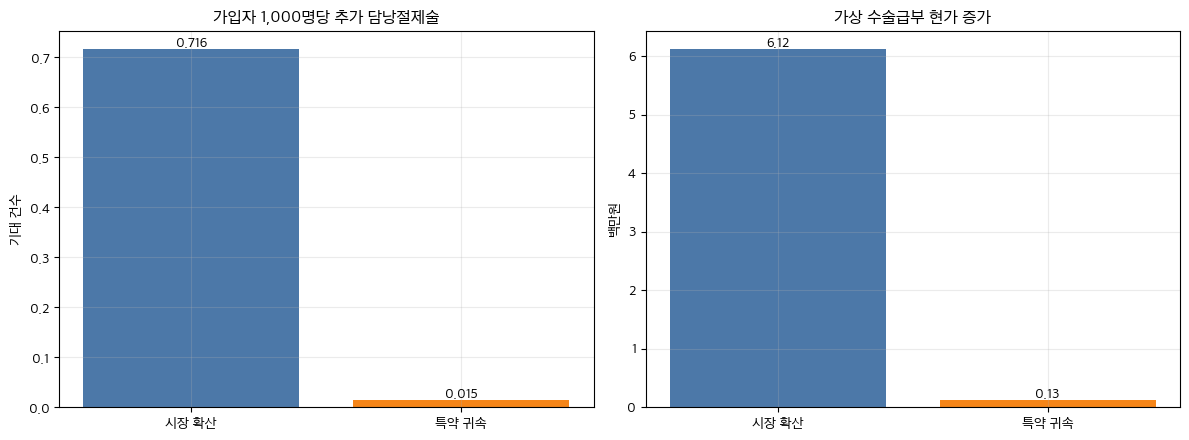

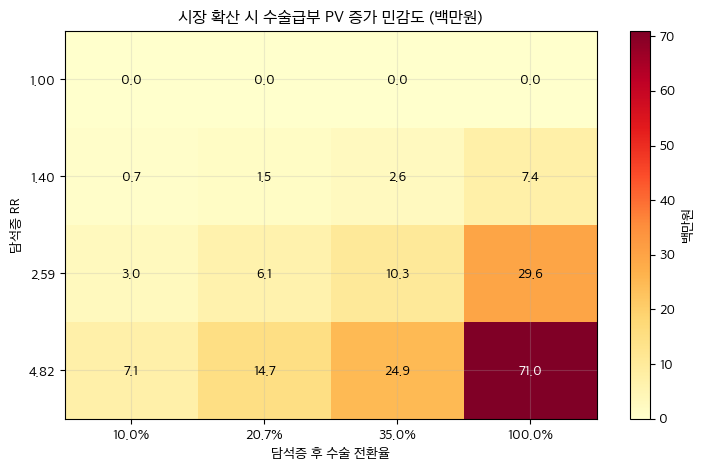

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

labels = ['시장 확산', '특약 귀속']
pv_values = comparison['수술급부 현가 증가(원)'].to_numpy() / 1_000_000
surgery_values = comparison['추가 담낭절제술'].to_numpy()

axes[0].bar(labels, surgery_values, color=['#4C78A8', '#F58518'])
axes[0].set_title('가입자 1,000명당 추가 담낭절제술')
axes[0].set_ylabel('기대 건수')
for i, value in enumerate(surgery_values):
    axes[0].text(i, value, f'{value:.3f}', ha='center', va='bottom')

axes[1].bar(labels, pv_values, color=['#4C78A8', '#F58518'])
axes[1].set_title('가상 수술급부 현가 증가')
axes[1].set_ylabel('백만원')
for i, value in enumerate(pv_values):
    axes[1].text(i, value, f'{value:.2f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

rr_values = [1.00, RR_LOW, RR_BASE, RR_HIGH]
surgery_values_grid = [0.10, SURGERY_SHARE, 0.35, 1.00]
heat = np.array([
    [compare_paths(*market_pair, rr=rr, surgery_share=p)['claim_pv'] / 1_000_000
     for p in surgery_values_grid]
    for rr in rr_values
])

fig, ax = plt.subplots(figsize=(7.5, 4.8))
im = ax.imshow(heat, cmap='YlOrRd', aspect='auto')
ax.set_xticks(range(len(surgery_values_grid)), [f'{p:.1%}' for p in surgery_values_grid])
ax.set_yticks(range(len(rr_values)), [f'{rr:.2f}' for rr in rr_values])
ax.set_xlabel('담석증 후 수술 전환율')
ax.set_ylabel('담석증 RR')
ax.set_title('시장 확산 시 수술급부 PV 증가 민감도 (백만원)')
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f'{heat[i, j]:.1f}', ha='center', va='center',
                color='white' if heat[i, j] > heat.max() * 0.55 else 'black')
fig.colorbar(im, ax=ax, label='백만원')
plt.tight_layout()
plt.show()

## 7. 보험사 포트폴리오 환산식

현재 숫자는 치료 적격 가상계약 1,000명이 모두 담낭수술 담보를 보유한다는 조건부 결과다. 전체 기존계약으로 확장할 때에는 다음 비중이 추가로 필요하다.

$$
\text{전체 담낭수술 급부 증가}
=\text{전체 기존계약 수}
\times\text{치료 적격·미사용 비중}
\times\text{담보 보유·유효 비중}
\times\text{적격계약 1건당 급부 증가}
$$

국민건강영양조사의 BMI 27 이상 비율 21.1%만으로 치료 적격·미사용 비중을 확정할 수 없다. BMI 27~30 구간은 동반질환 조건이 필요하고 보험가입자의 연령·성별·건강선택도 다르기 때문이다. 따라서 이 노트북에서는 전체 포트폴리오 금액을 임의로 제시하지 않는다.

## 8. 해석과 한계

| 구분 | 해석 |
|---|---|
| 무엇을 보여주나 | 치료 노출 증가가 담석증과 담낭절제술 급부에 미치는 조건부 증가 영향 |
| 시장효과와 특약효과 | 시장 확산과 특약 지원으로 추가된 시작자를 분리해 과대귀속을 방지 |
| 임상효과 | 메타분석 RR을 일정 위험배수로 근사했으며 개별 시험의 정확한 인년은 없음 |
| 수술 전환 | 국내 20.7%는 일반 담석증 코호트 값으로 위고비 사용자의 직접 관찰값이 아님 |
| 치료경로 | 기존 지속·중단·재개 모형을 연결했지만 담석증 이후 치료 중단은 별도 반영하지 않음 |
| 급부 정의 | 분석 시작 후 첫 담낭절제술 1회 지급의 가상 담보이며 실제 약관·인수기준과 다를 수 있음 |
| 국내 환산 | 적격 비중과 담보 보유율이 없어 전체 보험사 손익으로 확정하지 않음 |

Safwan과 Kommu는 담낭질환 위험이 증가하는 방향을 공통으로 보이지만, 수술보험금 증가는 국내 수술 전환율과 실제 치료 노출량에 크게 좌우된다. 따라서 기준값 하나보다 민감도 범위를 함께 제시하는 것이 적절하다.

## 9. 결론과 공통모형 연결

1. 위고비 치료 노출이 늘면 담석증과 담낭절제술 급부는 증가하는 방향이다.
2. 시장 확산에 따른 증가와 약제비 특약에 귀속되는 증가는 크기가 다르므로 분리해야 한다.
3. 담낭수술 영향은 수술 전환율, 임상 RR, 위험 환산기간과 담보금액에 비례해 크게 변한다.
4. 공통모형에서는 사망·심혈관·담낭 모듈의 대상, 시작경로, 시간축, 할인율과 담보 보유율을 통일한다.

공통모형의 보험사 순영향은 다음 구조로 결합한다.

$$
\text{보험사 순영향}
=\text{특약 손익}
+\text{사망보험금 감소}
+\text{심혈관 사건급부 감소}
-\text{담낭수술 급부 증가}
$$

시장 확산의 산업 영향에는 `market_low → market_high`, 특약 자체의 귀속효과에는 `A → A+B` 경로를 각각 사용해야 한다.

## 10. 계산 검증

In [6]:
neutral = compare_paths(*market_pair, rr=1.0)
half_benefit = compare_paths(*market_pair, benefit=BENEFIT / 2)
base_result = compare_paths(*market_pair)
double_conversion = compare_paths(*market_pair, surgery_share=SURGERY_SHARE * 2)

checks = {
    '국내 기준 전환율 재현': math.isclose(SURGERY_SHARE, 2706 / 13069, rel_tol=0, abs_tol=1e-15),
    '고확산 치료노출이 저확산보다 큼': paths[('market_high', 'no')]['on_treatment'].sum() > paths[('market_low', 'no')]['on_treatment'].sum(),
    '특약 있음 치료노출이 특약 없음보다 큼': paths[('base', 'yes')]['on_treatment'].sum() > paths[('base', 'no')]['on_treatment'].sum(),
    'RR=1이면 추가 급부 0': abs(neutral['claim_pv']) < 1e-8,
    '급부 절반이면 PV 절반': math.isclose(half_benefit['claim_pv'], base_result['claim_pv'] / 2, rel_tol=1e-12),
    '수술 전환율 2배이면 수술건수 2배': math.isclose(double_conversion['extra_surgeries'], base_result['extra_surgeries'] * 2, rel_tol=1e-12),
    '시장효과가 특약 귀속효과보다 큼': comparison.loc[0, '수술급부 현가 증가(원)'] > comparison.loc[1, '수술급부 현가 증가(원)'],
    '모든 경로의 기대인원 보존': all(
        treatment_model.validate_expected_path(result)['passed'] for result in paths.values()
    ),
}

validation = pd.DataFrame({'검증': checks.keys(), '통과': checks.values()})
display(validation)
assert all(checks.values())
print(f'검증 {sum(checks.values())}/{len(checks)} 통과')

,검증,통과
0,국내 기준 전환율 재현,True
1,고확산 치료노출이 저확산보다 큼,True
2,특약 있음 치료노출이 특약 없음보다 큼,True
3,RR=1이면 추가 급부 0,True
4,급부 절반이면 PV 절반,True
5,수술 전환율 2배이면 수술건수 2배,True
6,시장효과가 특약 귀속효과보다 큼,True
7,모든 경로의 기대인원 보존,True


검증 8/8 통과
